# Do the BUS→BS ensembles find subtle patterns better? — Walmart, Favorita, M5
Reads `results_v3/` (copy the Kaggle `results_v3/m5_large_*.csv` files in as well, if that notebook was run there).

In [1]:
import glob
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option("display.width", 250)
pd.set_option("display.max_columns", 40)
pd.set_option("display.max_colwidth", 110)


def load(kind):
    files = sorted(glob.glob(f"results_v3/*_{kind}.csv"))
    return pd.concat([pd.read_csv(f) for f in files], ignore_index=True) if files else pd.DataFrame()


main, dfd, subgroups, e1, e2 = load("main"), load("dfd"), load("subgroups"), load("e1"), load("e2")
DATASETS = list(main["dataset"].unique())
display(main.groupby("dataset", sort=False)[["N", "T", "distance_time_s"]].first().round(2))

,N,T,distance_time_s
dataset,,,
favorita,1100,910,6.20
m5,6581,1238,47.47
walmart,2566,143,10.73


## 1. Real data: steps, runtime and quality relative to unpruned BS (pruned runs)

In [2]:
reference = main[(main["method"] == "BS") & (~main["prune"])].set_index(["dataset", "measure"])
for column, source in [("evaluated_vs_BS", "evaluated"), ("runtime_vs_BS", "runtime_s"), ("avg_quality_vs_BS", "avg_quality")]:
    main[column] = [row[source] / reference.loc[(row["dataset"], row["measure"]), source] for _, row in main.iterrows()]
display(main[main["prune"]].pivot_table(index=["dataset", "measure"], columns="method",
                                        values=["evaluated_vs_BS", "runtime_vs_BS", "avg_quality_vs_BS"]).round(2))

avg_quality_vs_BS                                       evaluated_vs_BS                                       runtime_vs_BS                                      
method                          BS   BUS BUS-α BUS→BS per-MC BUS→BS pool              BS   BUS BUS-α BUS→BS per-MC BUS→BS pool            BS   BUS BUS-α BUS→BS per-MC BUS→BS pool
dataset  measure                                                                                                                                                                  
favorita M1                    1.0  0.88  0.88          0.88        0.92            0.93  0.33  0.33          0.34        0.64          1.23  0.37  0.36          1.09        0.92
         M2                    1.0  0.87  0.87          0.87        0.92            1.00  0.32  0.32          0.33        0.64          0.66  0.18  0.20          0.53        0.53
         M3                    1.0  1.00  1.00          1.00        0.99            0.88  1.06  1.28          0.92        0.60          0.92  0.96  0.73          2.02        0.80
m5       M1                    1.0  0.70  0.70          0.70        0.96            1.00  0.32  0.37          0.27        0.56          0.93  0.99  1.56          1.52        1.75
         M2                    1.0  0.68  0.69          0.69        0.96            1.00  0.34  0.39          0.29        0.55          0.86  0.87  0.99          1.38        1.30
         M3                    1.0  0.99  0.99          0.99        1.00            0.96  0.62  0.84          0.46        0.72          0.92  0.88  1.11          1.08        1.06
walmart  M1                    1.0  0.99  0.99          0.97        0.95            0.94  1.15  1.15          0.69        0.56          0.87  1.00  1.06          2.11        0.80
         M2                    1.0  0.99  0.99          0.96        0.94            0.95  1.10  1.10          0.63        0.55          0.96  0.91  1.03          2.04        0.76
         M3                    1.0  1.00  1.00          1.00        1.00            0.82  3.92  3.91          0.85        0.49          0.98  1.17  1.20          0.75        0.55

## 2. Significance: 500-run DFD (M2, pruned)

In [3]:
display(dfd.round(3))
display(subgroups[(subgroups["measure"] == "M2") & (subgroups["p_value"] < 0.05)]
        .groupby(["dataset", "description"])
        .agg(methods=("method", lambda s: ", ".join(sorted(set(s)))), p_value=("p_value", "min"),
             excess_relative=("excess_relative", "first"), pct_of_normal=("pct_of_normal", "first"),
             complement_pct=("complement_pct_of_normal", "first"), coverage_n=("coverage_n", "first"),
             n_stores=("n_stores", "first"), lift=("lift", "first"), phi=("phi_cluster", "first")).round(3))

,dataset,method,nu,dfd_seconds,dfd_median,dfd_95,dfd_99,best_quality,n_significant_005,n_significant_001
0,favorita,BS,500,40.162,5.955388e+06,8.304606e+06,9.946312e+06,5.973674e+06,0,0
1,favorita,BUS,500,6.257,5.002631e+06,7.816623e+06,8.939821e+06,5.973674e+06,0,0
2,favorita,BUS-α,500,6.206,5.002631e+06,7.816623e+06,8.939821e+06,5.973674e+06,0,0
3,favorita,BUS→BS pool,500,25.148,5.445708e+06,7.816623e+06,9.250338e+06,5.973674e+06,0,0
4,favorita,BUS→BS per-MC,500,23.970,5.002631e+06,7.816623e+06,8.939821e+06,5.973674e+06,0,0
5,m5,BS,500,234.885,5.665201e+05,8.589823e+05,9.761418e+05,5.729939e+05,0,0
6,m5,BUS,500,77.951,5.204556e+05,8.104864e+05,9.497499e+05,3.283069e+05,0,0
7,m5,BUS-α,500,82.984,5.222687e+05,8.187274e+05,9.497499e+05,3.283069e+05,0,0
8,m5,BUS→BS pool,500,170.460,5.468595e+05,8.583497e+05,9.761418e+05,5.729939e+05,0,0
9,m5,BUS→BS per-MC,500,310.705,5.222687e+05,8.187274e+05,9.497499e+05,3.283069e+05,0,0


,,methods,p_value,excess_relative,pct_of_normal,complement_pct,coverage_n,n_stores,lift,phi
dataset,description,,,,,,,,,
walmart,Temperature_volatility_cat = medium AND Fuel_Price_volatility_cat = medium AND Unemployment_mean_cat = medium,BUS→BS pool,0.05,-6.350184e+07,-4.477,0.935,380,6,1.161,1.102


## 3. Experiment 1: planted subgroups — share in the top-20 (found) and ranked first, per effect size and pattern

In [4]:
for frame in (e1, e2):
    frame["found"] = frame["rank"] <= 20
    frame["top1"] = frame["rank"] == 1
for metric in ["found", "top1"]:
    print(f"\nshare {metric}")
    display(e1.pivot_table(index=["dataset", "pattern", "snr"], columns="method", values=metric).round(2))
print("\nmean rank when reported / evaluations / runtime (s)")
display(e1.groupby(["dataset", "method"], sort=False)[["rank", "evaluated", "runtime_s"]].mean().round(2))
print("\neffect of outliers and description length (share found)")
display(e1.pivot_table(index=["dataset", "outliers", "lits"], columns="method", values="found").round(2))


share found

share top1

mean rank when reported / evaluations / runtime (s)

effect of outliers and description length (share found)


method                  BS  BS w=10   BUS  BUS-α  BUS→BS per-MC  BUS→BS pool
dataset  pattern snr                                                        
favorita level   1    0.25     0.25  0.00   0.00           0.00         0.25
                 2    0.00     0.00  0.00   0.00           0.00         0.12
                 4    0.88     0.88  0.00   0.00           0.00         0.50
                 8    1.00     1.00  0.25   0.25           0.25         0.88
         timing  1    0.12     0.00  0.12   0.12           0.12         0.12
                 2    0.00     0.00  0.00   0.00           0.00         0.00
                 4    0.00     0.25  0.00   0.00           0.00         0.00
                 8    0.00     0.00  0.00   0.00           0.00         0.00
         trend   1    0.12     0.12  0.00   0.00           0.00         0.00
                 2    0.25     0.25  0.25   0.25           0.25         0.25
                 4    0.62     0.62  0.25   0.25           0.25         0.38
                 8    1.00     1.00  0.12   0.12           0.12         0.62
m5       level   1    0.00     0.00  0.00   0.00           0.00         0.00
                 2    0.00     0.00  0.00   0.00           0.00         0.00
                 4    0.50     0.38  0.00   0.12           0.12         0.38
                 8    0.62     0.62  0.25   0.25           0.25         0.50
         timing  1    0.00     0.00  0.00   0.00           0.00         0.00
                 2    0.00     0.00  0.00   0.00           0.00         0.00
                 4    0.00     0.00  0.00   0.00           0.00         0.00
                 8    0.00     0.00  0.00   0.00           0.00         0.00
         trend   1    0.25     0.12  0.00   0.00           0.00         0.25
                 2    0.00     0.12  0.00   0.00           0.00         0.00
                 4    0.12     0.12  0.00   0.00           0.00         0.00
                 8    0.75     0.88  0.12   0.12           0.12         0.50
walmart  level   1    0.00     0.00  0.00   0.00           0.00         0.00
                 2    0.00     0.00  0.00   0.00           0.00         0.00
                 4    0.62     0.50  0.62   0.62           0.50         0.25
                 8    0.88     0.88  0.25   0.38           0.38         0.38
         timing  1    0.38     0.25  0.25   0.25           0.38         0.38
                 2    0.00     0.12  0.00   0.00           0.00         0.00
                 4    0.00     0.12  0.12   0.12           0.12         0.12
                 8    0.25     0.12  0.25   0.25           0.25         0.12
         trend   1    0.00     0.00  0.00   0.00           0.00         0.00
                 2    0.25     0.12  0.00   0.00           0.00         0.12
                 4    0.12     0.00  0.00   0.00           0.00         0.25
                 8    1.00     1.00  0.12   0.12           0.12         0.50

method                  BS  BS w=10   BUS  BUS-α  BUS→BS per-MC  BUS→BS pool
dataset  pattern snr                                                        
favorita level   1    0.00     0.00  0.00   0.00           0.00         0.00
                 2    0.00     0.00  0.00   0.00           0.00         0.00
                 4    0.12     0.12  0.00   0.00           0.00         0.00
                 8    0.12     0.12  0.00   0.00           0.00         0.12
         timing  1    0.00     0.00  0.00   0.00           0.00         0.00
                 2    0.00     0.00  0.00   0.00           0.00         0.00
                 4    0.00     0.00  0.00   0.00           0.00         0.00
                 8    0.00     0.00  0.00   0.00           0.00         0.00
         trend   1    0.12     0.12  0.00   0.00           0.00         0.00
                 2    0.12     0.12  0.12   0.12           0.12         0.12
                 4    0.25     0.25  0.12   0.12           0.12         0.25
                 8    0.38     0.38  0.12   0.12           0.12         0.38
m5       level   1    0.00     0.00  0.00   0.00           0.00         0.00
                 2    0.00     0.00  0.00   0.00           0.00         0.00
                 4    0.00     0.00  0.00   0.00           0.00         0.12
                 8    0.12     0.12  0.00   0.00           0.00         0.00
         timing  1    0.00     0.00  0.00   0.00           0.00         0.00
                 2    0.00     0.00  0.00   0.00           0.00         0.00
                 4    0.00     0.00  0.00   0.00           0.00         0.00
                 8    0.00     0.00  0.00   0.00           0.00         0.00
         trend   1    0.00     0.00  0.00   0.00           0.00         0.00
                 2    0.00     0.00  0.00   0.00           0.00         0.00
                 4    0.00     0.00  0.00   0.00           0.00         0.00
                 8    0.00     0.00  0.00   0.00           0.00         0.00
walmart  level   1    0.00     0.00  0.00   0.00           0.00         0.00
                 2    0.00     0.00  0.00   0.00           0.00         0.00
                 4    0.00     0.00  0.00   0.00           0.00         0.00
                 8    0.12     0.12  0.00   0.00           0.00         0.00
         timing  1    0.00     0.00  0.00   0.00           0.00         0.00
                 2    0.00     0.00  0.00   0.00           0.00         0.00
                 4    0.00     0.00  0.00   0.00           0.00         0.00
                 8    0.00     0.00  0.00   0.00           0.00         0.00
         trend   1    0.00     0.00  0.00   0.00           0.00         0.00
                 2    0.00     0.00  0.00   0.00           0.00         0.00
                 4    0.00     0.00  0.00   0.00           0.00         0.00
                 8    0.12     0.25  0.00   0.00           0.00         0.12

rank  evaluated  runtime_s
dataset  method                                   
favorita BS             4.12     492.40       0.73
         BS w=10        4.54     223.01       0.25
         BUS            4.38     284.40       0.30
         BUS-α          4.00     294.66       0.35
         BUS→BS pool    4.32     396.36       0.58
         BUS→BS per-MC  3.88     278.32       0.74
m5       BS             5.89     803.90      11.99
         BS w=10        6.17     361.68       3.78
         BUS            3.00     455.39       7.33
         BUS-α          4.00     504.18      10.49
         BUS→BS pool    6.00     631.25      11.48
         BUS→BS per-MC  4.00     416.09      12.99
walmart  BS             9.00     611.35       2.73
         BS w=10        7.96     276.69       0.91
         BUS            9.00     726.00       3.94
         BUS-α          8.79     728.91       4.07
         BUS→BS pool    6.59     433.93       2.53
         BUS→BS per-MC  8.79     514.89       4.37

method                    BS  BS w=10   BUS  BUS-α  BUS→BS per-MC  BUS→BS pool
dataset  outliers lits                                                        
favorita 0.0      2     0.42     0.46  0.17   0.17           0.17         0.25
                  3     0.42     0.42  0.08   0.08           0.08         0.33
         0.2      2     0.33     0.33  0.04   0.04           0.04         0.25
                  3     0.25     0.25  0.04   0.04           0.04         0.21
m5       0.0      2     0.29     0.33  0.04   0.04           0.04         0.17
                  3     0.12     0.12  0.00   0.00           0.00         0.12
         0.2      2     0.12     0.17  0.04   0.04           0.04         0.04
                  3     0.21     0.12  0.04   0.08           0.08         0.21
walmart  0.0      2     0.42     0.33  0.25   0.25           0.21         0.29
                  3     0.29     0.29  0.12   0.17           0.17         0.21
         0.2      2     0.21     0.21  0.00   0.00           0.04         0.08
                  3     0.25     0.21  0.17   0.17           0.17         0.12

## 4. Experiment 2: interaction-only planted subgroups

In [5]:
display(e2.pivot_table(index=["dataset", "snr"], columns="method", values=["found", "top1"]).round(2))
print("planted effect sizes (share of normal sales) per dataset and snr")
display(pd.concat([e1, e2]).groupby(["dataset", "pattern", "snr"])["delta"].mean().unstack().round(4))
display(e2.groupby(["dataset", "method"], sort=False)[["rank", "evaluated", "runtime_s"]].mean().round(2))

planted effect sizes (share of normal sales) per dataset and snr


found                                                               top1                                                             
method          BS BS w=10 BS w=20 BS w=5   BUS BUS-α BUS→BS per-MC BUS→BS pool    BS BS w=10 BS w=20 BS w=5   BUS BUS-α BUS→BS per-MC BUS→BS pool
dataset  snr                                                                                                                                      
favorita 4    1.00    0.67    0.67   0.00  0.00  0.00          0.00        0.33  0.33    0.33    0.33   0.00  0.00  0.00          0.00        0.33
         8    1.00    0.67    1.00   0.67  0.33  0.33          0.33        1.00  0.33    0.33    0.33   0.33  0.33  0.33          0.33        0.33
m5       4    0.67    0.67    0.67   0.33  0.00  0.00          0.00        0.67  0.33    0.33    0.33   0.33  0.00  0.00          0.00        0.33
         8    1.00    1.00    1.00   1.00  0.33  0.33          0.33        0.33  1.00    1.00    1.00   1.00  0.33  0.33          0.33        0.33
walmart  4    0.67    0.67    0.67   0.67  0.00  0.33          0.33        0.67  0.00    0.00    0.00   0.00  0.00  0.00          0.00        0.00
         8    1.00    0.67    1.00   0.33  0.33  0.33          0.33        0.33  0.00    0.00    0.00   0.00  0.00  0.00          0.00        0.00

snr                        1       2       4       8
dataset  pattern                                    
favorita interaction     NaN     NaN  0.3676  0.7352
         level        0.0919  0.1838  0.3676  0.7352
         timing       0.0357  0.0715  0.1430  0.2860
         trend        0.0919  0.1838  0.3676  0.7352
m5       interaction     NaN     NaN  0.1646  0.3292
         level        0.0412  0.0823  0.1646  0.3292
         timing       0.0074  0.0148  0.0296  0.0592
         trend        0.0412  0.0823  0.1646  0.3292
walmart  interaction     NaN     NaN  0.1699  0.3398
         level        0.0425  0.0850  0.1699  0.3398
         timing       0.0127  0.0254  0.0507  0.1014
         trend        0.0425  0.0850  0.1699  0.3398

rank  evaluated  runtime_s
dataset  method                                   
favorita BS w=5         3.00     203.83       0.13
         BS w=10        4.75     299.00       0.21
         BS w=20        4.60     420.50       0.31
         BS             4.17     553.17       0.51
         BUS            1.00     206.00       0.15
         BUS-α          1.00     206.50       0.17
         BUS→BS pool    2.75     463.17       0.44
         BUS→BS per-MC  1.00     216.00       0.35
m5       BS w=5         1.00     255.50       0.56
         BS w=10        1.20     421.33       1.01
         BS w=20        1.20     647.50       1.68
         BS             1.20     873.67       2.90
         BUS            1.00     452.83       2.89
         BUS-α          1.00     474.83       4.29
         BUS→BS pool    1.33     617.00       4.91
         BUS→BS per-MC  1.00     389.00       5.83
walmart  BS w=5         3.00     215.50       0.39
         BS w=10        4.25     320.33       0.68
         BS w=20        2.80     461.17       1.11
         BS             2.80     657.83       2.04
         BUS            2.00     599.50       1.81
         BUS-α          3.50     601.50       2.01
         BUS→BS pool    2.00     504.33       1.80
         BUS→BS per-MC  3.50     502.83       3.90

## 5. Experiment 3: equal budget / anytime
Share of planted subgroups that would be in the top-20 if each method were stopped after B quality evaluations
(left) or t seconds (right).

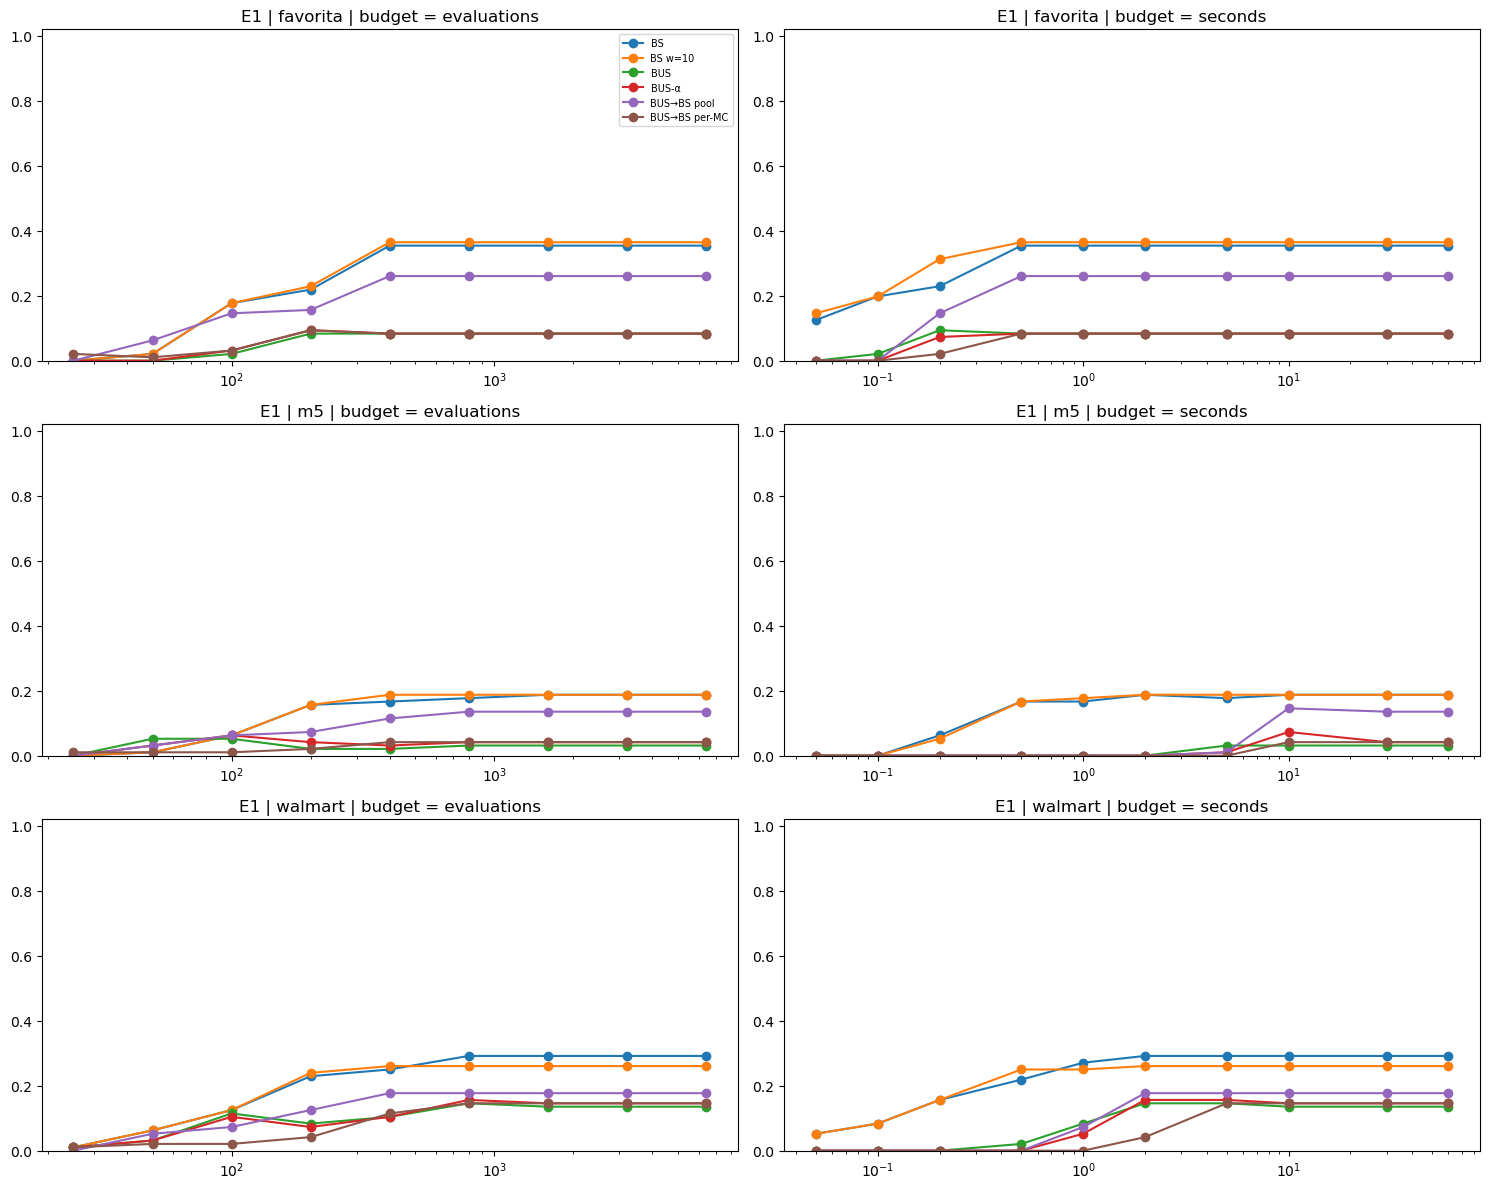

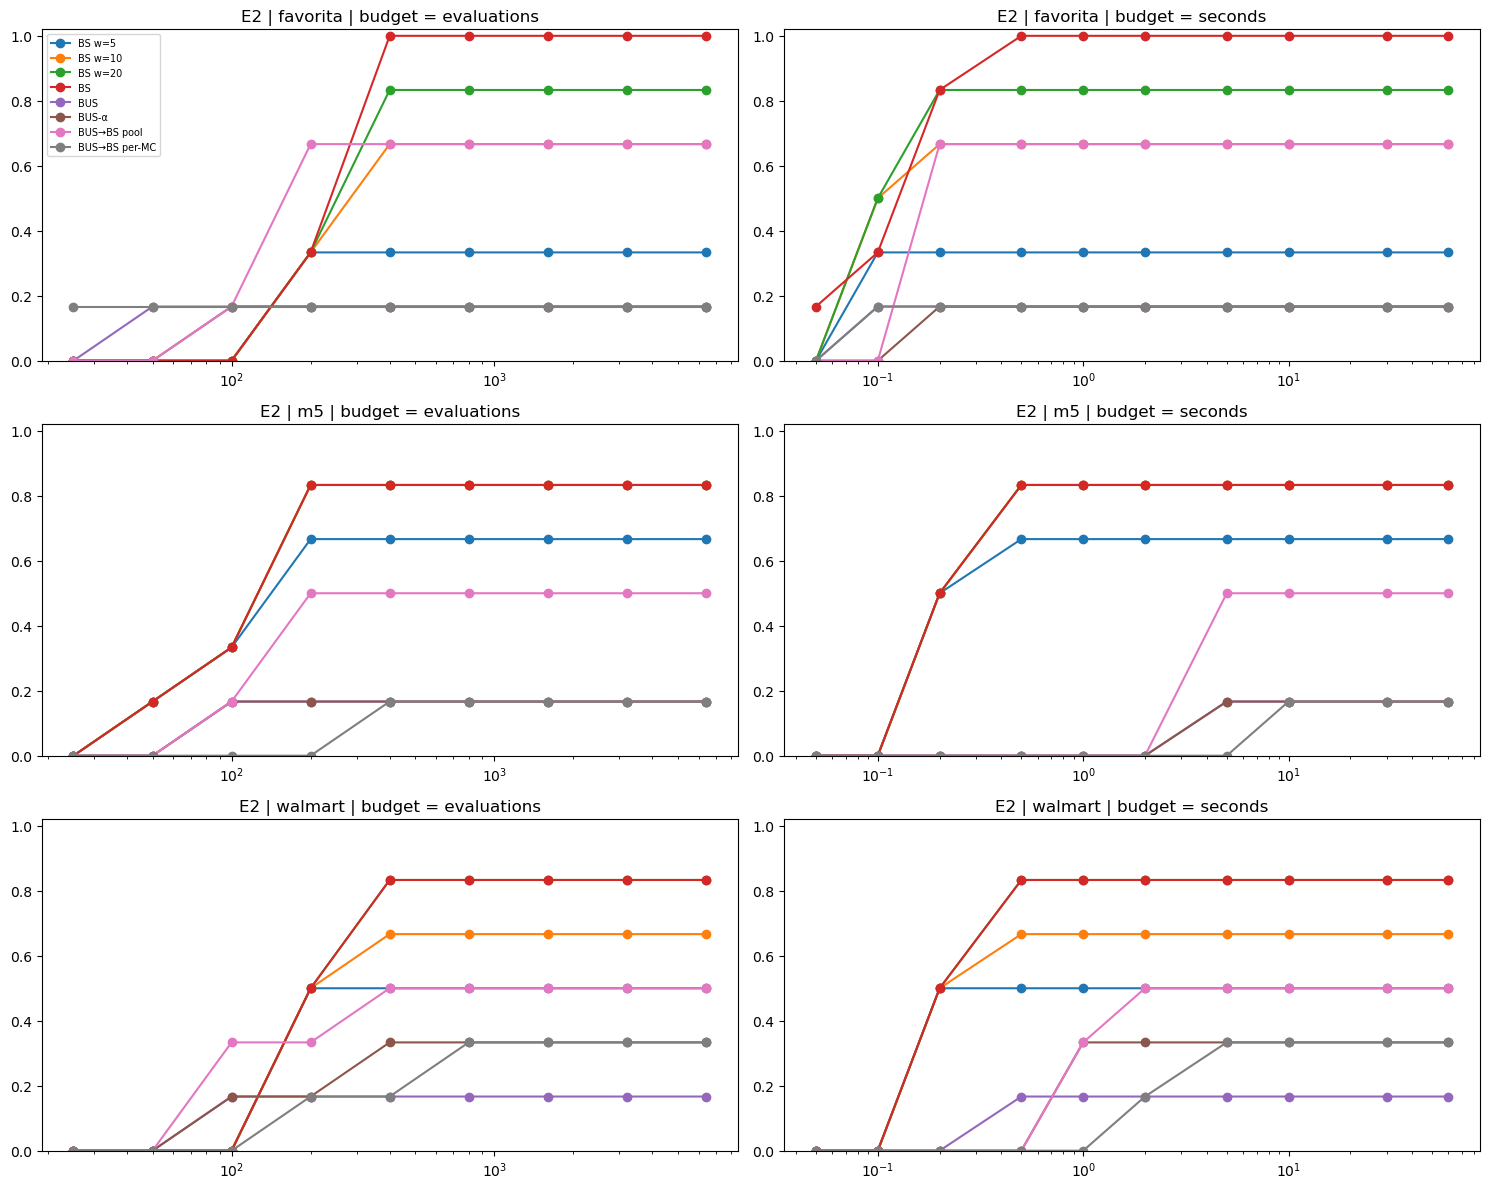

,experiment,dataset,method,top20@100,top20@400,top20@1600,top20@0.5s,top20@2s,top20@10s
0,E1,favorita,BS,0.18,0.35,0.35,0.35,0.35,0.35
1,E1,favorita,BS w=10,0.18,0.36,0.36,0.36,0.36,0.36
2,E1,favorita,BUS,0.02,0.08,0.08,0.08,0.08,0.08
3,E1,favorita,BUS-α,0.03,0.08,0.08,0.08,0.08,0.08
4,E1,favorita,BUS→BS pool,0.15,0.26,0.26,0.26,0.26,0.26
5,E1,favorita,BUS→BS per-MC,0.03,0.08,0.08,0.08,0.08,0.08
6,E1,m5,BS,0.06,0.17,0.19,0.17,0.19,0.19
7,E1,m5,BS w=10,0.06,0.19,0.19,0.17,0.19,0.19
8,E1,m5,BUS,0.05,0.02,0.03,0.00,0.00,0.03
9,E1,m5,BUS-α,0.06,0.03,0.04,0.00,0.00,0.07


In [6]:
BUDGETS = [25, 50, 100, 200, 400, 800, 1600, 3200, 6400]
SECONDS = [0.05, 0.1, 0.2, 0.5, 1, 2, 5, 10, 30, 60]
for name, df in [("E1", e1), ("E2", e2)]:
    fig, axes = plt.subplots(len(DATASETS), 2, figsize=(15, 4 * len(DATASETS)), squeeze=False)
    for row, dataset in enumerate(DATASETS):
        sub = df[df["dataset"] == dataset]
        for col, (grid, suffix) in enumerate([(BUDGETS, ""), (SECONDS, "s")]):
            for method, g in sub.groupby("method", sort=False):
                axes[row, col].plot(grid, [np.mean(g[f"rank_at_{b}{suffix}"] <= 20) for b in grid], marker="o", label=method)
            axes[row, col].set_xscale("log")
            axes[row, col].set_ylim(0, 1.02)
            axes[row, col].set_title(f"{name} | {dataset} | budget = {'evaluations' if col == 0 else 'seconds'}")
    axes[0, 0].legend(fontsize=7)
    plt.tight_layout()
    plt.show()

rows = []
for name, df in [("E1", e1), ("E2", e2)]:
    for (dataset, method), g in df.groupby(["dataset", "method"], sort=False):
        rows.append({"experiment": name, "dataset": dataset, "method": method,
                     **{f"top20@{b}": np.mean(g[f"rank_at_{b}"] <= 20) for b in [100, 400, 1600]},
                     **{f"top20@{t}s": np.mean(g[f"rank_at_{t}s"] <= 20) for t in [0.5, 2, 10]}})
display(pd.DataFrame(rows).round(2))

## Conclusions (Walmart 2,566 × 143 weeks, Favorita 1,100 × 910 days, M5 6,581 × 1,238 days; 500-run DFDs; 576 E1 + 48 E2 runs per dataset)
**Experiment 1, planted subgroups (share ranked in the top-20):** plain beam search is best on every dataset (Walmart 0.29, Favorita 0.35, M5 0.19). BS with beam 10 matches it (0.26 / 0.36 / 0.19) with ~45% of the evaluations and ~30% of the runtime. The pool ensemble comes second (0.18 / 0.26 / 0.14). BUS, BUS-α and the per-MC ensemble are last (0.03–0.15). Timing patterns (M3) are almost never ranked by any method at these effect sizes.

**Experiment 2, interaction-only patterns:** the hypothesis that BUS recovers A∧B where greedy BS drops A and B is **not supported**. BS with beam ≥ 10 finds 67–100%, the pool ensemble 50–67%, and the BUS family 17–33%. With only 41–67 conditions, BS's first level evaluates every single condition, and A or B survives in a beam of 10.

**Experiment 3, equal budget:** at equal evaluations BS is never behind. At equal time it is clearly ahead, because every BUS variant first spends 2–4 s on M5 (0.3–0.9 s on Walmart) selecting pairs before its first evaluation.

**Real data:** on M5, BUS / BUS-α / per-MC miss BS's best money subgroup (57% of its quality; 3–4 of BS's top-20), while the pool ensemble finds it (14–15/20). Significance (500 runs): Walmart's −$63.5M subgroup is borderline (p ≈ 0.05). Nothing is significant on Favorita or M5. M5's top subgroup is Texas FOODS_3, −4.9% vs peers, p = 0.48.

**Why BUS loses here:** (1) it keeps only the 200 most similar-and-unusual pairs out of 0.6–22 million, and real noise and outlier records fill that list; (2) for money patterns the signal is a subgroup's *summed* excess, not how alike two curves are; (3) the descriptor spaces are small enough for beam search to cover them.
